# ABC Tech ITSM AI

## Project Overview

This project analyzes historical IT Service Management (ITSM) incidents using data analytics and machine learning.

### Objectives
- Analyze incident patterns and priority distributions.
- Develop a model to identify potentially high-priority incidents.
- Forecast daily ticket volumes.
- Present results through an interactive Streamlit dashboard.

### Technologies
Python, Pandas, NumPy, Matplotlib, Seaborn, Scikit-learn, Plotly, and Streamlit.

### Data Limitations
The dataset contains historical records from 2012–2014. Predictions are experimental and should not be interpreted as validated forecasts for current production operations.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

PROJECT_DIR = Path.cwd()

# Handle running the notebook from either the project root or notebooks folder
if not (PROJECT_DIR / "data" / "itsm_dataset.csv").exists():
    PROJECT_DIR = PROJECT_DIR.parent

DATA_PATH = PROJECT_DIR / "data" / "itsm_dataset.csv"

df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

df.head()

Dataset shape: (46606, 25)

Column names:
['CI_Name', 'CI_Cat', 'CI_Subcat', 'WBS', 'Incident_ID', 'Status', 'Impact', 'Urgency', 'Priority', 'number_cnt', 'Category', 'KB_number', 'Alert_Status', 'No_of_Reassignments', 'Open_Time', 'Reopen_Time', 'Resolved_Time', 'Close_Time', 'Handle_Time_hrs', 'Closure_Code', 'No_of_Related_Interactions', 'Related_Interaction', 'No_of_Related_Incidents', 'No_of_Related_Changes', 'Related_Change']


C:\Users\prana\AppData\Local\Temp\ipykernel_5656\1056538797.py:14: DtypeWarning: Columns (7: Urgency) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(DATA_PATH)


,CI_Name,CI_Cat,CI_Subcat,WBS,Incident_ID,Status,Impact,Urgency,Priority,number_cnt,...,Reopen_Time,Resolved_Time,Close_Time,Handle_Time_hrs,Closure_Code,No_of_Related_Interactions,Related_Interaction,No_of_Related_Incidents,No_of_Related_Changes,Related_Change
0,SUB000508,subapplication,Web Based Application,WBS000162,IM0000004,Closed,4,4,4.0,0.601292,...,NaN,04-11-2013 13:50,04-11-2013 13:51,"3,87,16,91,111",Other,1.0,SD0000007,2.0,NaN,NaN
1,WBA000124,application,Web Based Application,WBS000088,IM0000005,Closed,3,3,3.0,0.415050,...,02-12-2013 12:31,02-12-2013 12:36,02-12-2013 12:36,"4,35,47,86,389",Software,1.0,SD0000011,1.0,NaN,NaN
2,DTA000024,application,Desktop Application,WBS000092,IM0000006,Closed,NS,3,NaN,0.517551,...,NaN,13-01-2014 15:12,13-01-2014 15:13,"4,84,31,19,444",No error - works as designed,1.0,SD0000017,NaN,NaN,NaN
3,WBA000124,application,Web Based Application,WBS000088,IM0000011,Closed,4,4,4.0,0.642927,...,NaN,14-11-2013 09:31,14-11-2013 09:31,"4,32,18,33,333",Operator error,1.0,SD0000025,NaN,NaN,NaN
4,WBA000124,application,Web Based Application,WBS000088,IM0000012,Closed,4,4,4.0,0.345258,...,NaN,08-11-2013 13:55,08-11-2013 13:55,"3,38,39,03,333",Other,1.0,SD0000029,NaN,NaN,NaN


## 2. Data Inspection and Quality Analysis

This section examines the dataset structure, data types, missing values, duplicate records, and statistical summaries to understand data quality before preprocessing and model development.m

In [2]:
# Dataset dimensions
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

# Column names and data types
print("\nDataset information:")
df.info()

# Missing values
missing_summary = df.isnull().sum().sort_values(ascending=False)

print("\nColumns with the most missing values:")
display(missing_summary[missing_summary > 0].to_frame("Missing_Values"))

# Duplicate records
print("\nDuplicate rows:", df.duplicated().sum())

# Statistical summary
display(df.describe(include="all").T)

Number of rows: 46606
Number of columns: 25

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 46606 entries, 0 to 46605
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   CI_Name                     46606 non-null  str    
 1   CI_Cat                      46495 non-null  str    
 2   CI_Subcat                   46495 non-null  str    
 3   WBS                         46606 non-null  str    
 4   Incident_ID                 46606 non-null  str    
 5   Status                      46606 non-null  str    
 6   Impact                      46606 non-null  str    
 7   Urgency                     46606 non-null  object 
 8   Priority                    45226 non-null  float64
 9   number_cnt                  46606 non-null  float64
 10  Category                    46606 non-null  str    
 11  KB_number                   46606 non-null  str    
 12  Alert_Status                46606

,Missing_Values
Related_Change,46046
No_of_Related_Changes,46046
No_of_Related_Incidents,45384
Reopen_Time,44322
Resolved_Time,1780
Priority,1380
Closure_Code,460
No_of_Related_Interactions,114
CI_Subcat,111
CI_Cat,111



Duplicate rows: 0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
CI_Name,46606,3019,SUB000456,3050,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CI_Cat,46495,12,application,32900,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CI_Subcat,46495,64,Server Based Application,18811,NaN,NaN,NaN,NaN,NaN,NaN,NaN
WBS,46606,274,WBS000073,13342,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Incident_ID,46606,46606,IM0000004,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Status,46606,2,Closed,46597,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Impact,46606,6,4,22556,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Urgency,46606.0,11.0,4.0,15526.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Priority,45226.0,NaN,NaN,NaN,4.215805,0.705624,1.0,4.0,4.0,5.0,5.0
number_cnt,46606.0,NaN,NaN,NaN,0.499658,0.288634,0.000023,0.248213,0.500269,0.749094,0.999997


## 3. Exploratory Data Analysis (EDA)

Exploratory Data Analysis is used to identify patterns in IT service incidents, understand priority distributions, examine frequently reported incident categories, and analyze ticket volumes over time.

C:\Users\prana\AppData\Local\Temp\ipykernel_5656\308058081.py:7: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  priority_counts = df["Priority"].fillna("Missing").astype(str).value_counts()


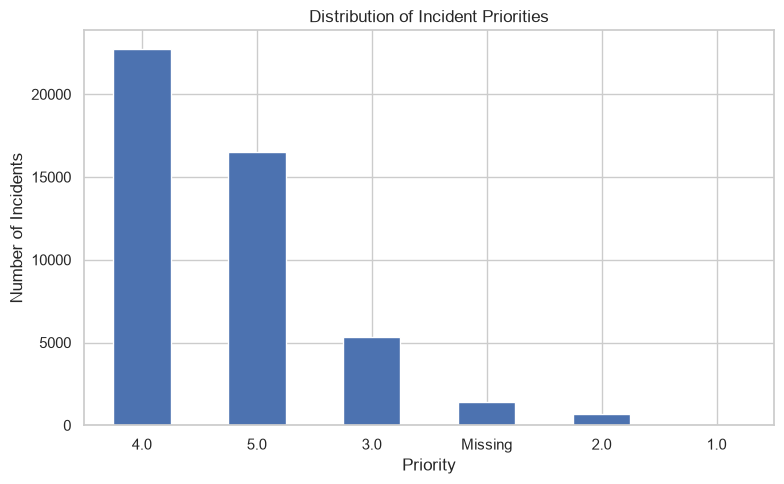

,Incident_Count
Priority,
4.0,22717
5.0,16486
3.0,5323
Missing,1380
2.0,697
1.0,3


In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Priority distribution, including missing values
priority_counts = df["Priority"].fillna("Missing").astype(str).value_counts()

plt.figure(figsize=(8, 5))
priority_counts.plot(kind="bar")
plt.title("Distribution of Incident Priorities")
plt.xlabel("Priority")
plt.ylabel("Number of Incidents")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

display(priority_counts.to_frame("Incident_Count"))

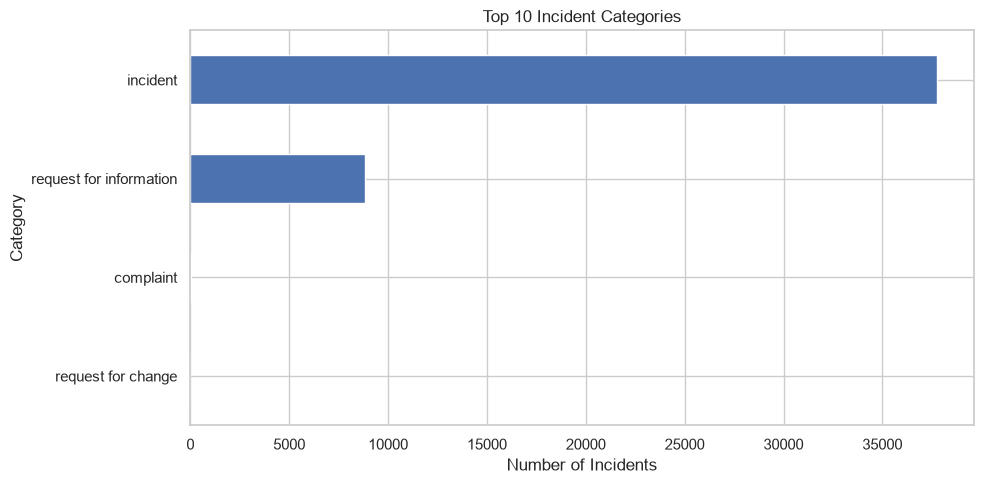

,Incident_Count
Category,
incident,37748
request for information,8846
complaint,11
request for change,1


In [4]:
# Top 10 incident categories
category_counts = df["Category"].fillna("Missing").value_counts().head(10)

plt.figure(figsize=(10, 5))
category_counts.sort_values().plot(kind="barh")
plt.title("Top 10 Incident Categories")
plt.xlabel("Number of Incidents")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

display(category_counts.to_frame("Incident_Count"))

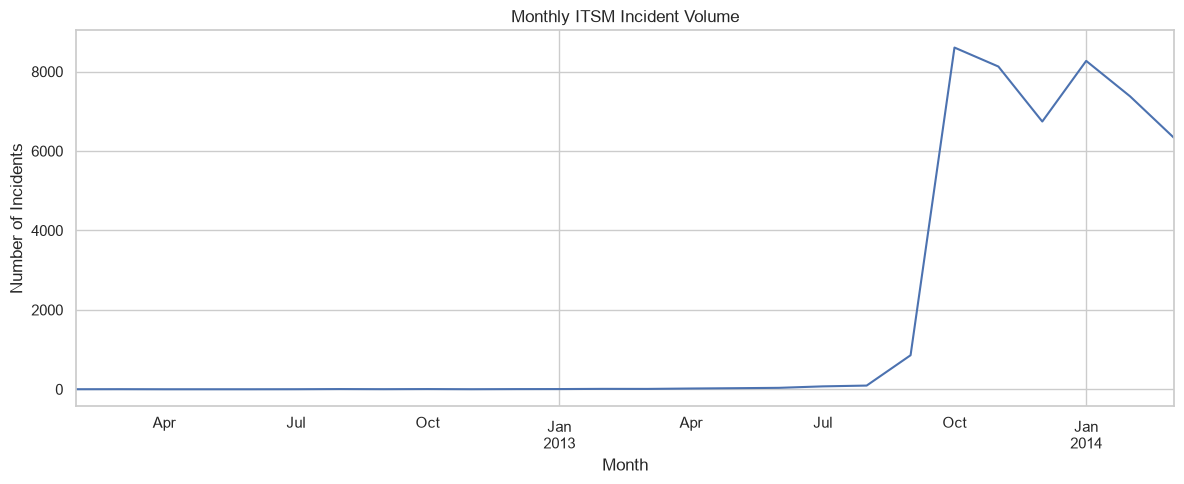

,Incident_Count
Open_Time_Parsed,
2012-02-01,1
2012-03-01,2
2012-04-01,0
2012-05-01,0
2012-06-01,0
2012-07-01,1
2012-08-01,5
2012-09-01,2
2012-10-01,5


In [5]:
# Parse incident opening timestamps
df["Open_Time_Parsed"] = pd.to_datetime(
    df["Open_Time"],
    errors="coerce",
    dayfirst=True
)

monthly_incidents = (
    df.dropna(subset=["Open_Time_Parsed"])
      .set_index("Open_Time_Parsed")
      .resample("MS")
      .size()
)

plt.figure(figsize=(12, 5))
monthly_incidents.plot()
plt.title("Monthly ITSM Incident Volume")
plt.xlabel("Month")
plt.ylabel("Number of Incidents")
plt.tight_layout()
plt.show()

display(monthly_incidents.to_frame("Incident_Count"))

## 4. High-Priority Incident Classification

This section demonstrates the trained machine learning pipeline used to estimate whether an incident belongs to the high-priority class (Priority 1 or 2).

The model uses incident metadata: CI category, CI subcategory, incident category, opening weekday, and opening hour.

The trained model was evaluated chronologically to better represent prediction on later records. Its classification threshold was selected using a separate validation period.

In [6]:
from pathlib import Path
import joblib

MODEL_PATH = PROJECT_DIR / "models" / "priority_classifier.joblib"

priority_bundle = joblib.load(MODEL_PATH)

pipeline = priority_bundle["pipeline"]
threshold = priority_bundle["threshold"]
feature_columns = priority_bundle["feature_columns"]

print("Model loaded successfully.")
print("Feature columns:", feature_columns)
print("Classification threshold:", threshold)

Model loaded successfully.
Feature columns: ['CI_Cat', 'CI_Subcat', 'Category', 'Open_Weekday', 'Open_Hour']
Classification threshold: 0.9


In [7]:
# Use an existing incident as a demonstration example
example = df.iloc[[0]].copy()

# Build the exact feature set expected by the trained pipeline
example_features = pd.DataFrame({
    "CI_Cat": example["CI_Cat"].values,
    "CI_Subcat": example["CI_Subcat"].values,
    "Category": example["Category"].values,
    "Open_Weekday": example["Open_Time_Parsed"].dt.dayofweek.values,
    "Open_Hour": example["Open_Time_Parsed"].dt.hour.values
})[feature_columns]

probability = pipeline.predict_proba(example_features)[0, 1]
prediction = "High Priority (P1/P2)" if probability >= threshold else "Other Priority (P3/P4/P5)"

print("Estimated high-priority probability:", f"{probability:.2%}")
print("Decision threshold:", f"{threshold:.0%}")
print("Model classification:", prediction)

Estimated high-priority probability: 54.55%
Decision threshold: 90%
Model classification: Other Priority (P3/P4/P5)


C:\Users\prana\AppData\Local\Temp\ipykernel_5656\1460675134.py:9: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  "Open_Weekday": example["Open_Time_Parsed"].dt.dayofweek.values,


## 5. Daily ITSM Ticket Volume Forecasting

This section analyzes daily incident volumes and compares forecasting approaches.

The project evaluates:
- Previous-week baseline: predicts ticket volume using the count from seven days earlier.
- Weekday median baseline: uses historical median ticket volume for the corresponding weekday.
- Random Forest Regressor: predicts ticket volume using lagged counts, rolling averages, and calendar features.

Models were evaluated on a chronological test period to preserve time order and avoid random splitting of historical data.

In [8]:
comparison_path = PROJECT_DIR / "reports" / "forecast_model_comparison.csv"

forecast_comparison = pd.read_csv(comparison_path)

print("Forecasting model comparison:")
display(forecast_comparison)

Forecasting model comparison:


,Model,MAE,RMSE
0,Previous-week baseline,24.77,35.61
1,Random Forest,31.61,41.72
2,Weekday median,42.83,61.09


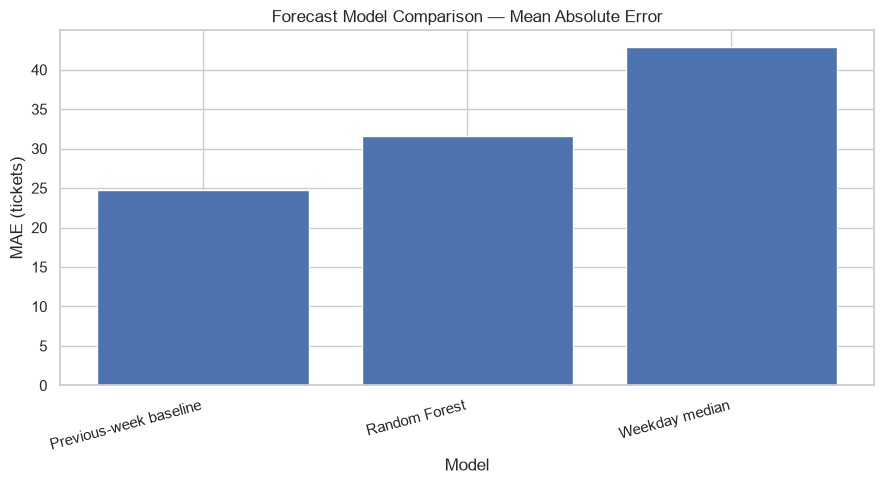

In [9]:
plt.figure(figsize=(9, 5))

plt.bar(
    forecast_comparison["Model"],
    forecast_comparison["MAE"]
)

plt.title("Forecast Model Comparison — Mean Absolute Error")
plt.xlabel("Model")
plt.ylabel("MAE (tickets)")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

## 6. Final Model Evaluation

The priority classifier was evaluated using a chronological train-test split. The decision threshold of 0.90 was selected using a separate validation period before final testing.

The positive class represents high-priority incidents (Priority 1 or 2). Precision measures how many predicted high-priority incidents were actually high priority, while recall measures how many actual high-priority incidents the model identified.

In [10]:
final_predictions_path = (
    PROJECT_DIR / "reports" / "priority_final_test_predictions.csv"
)

final_predictions = pd.read_csv(final_predictions_path)

print("Final test prediction file loaded.")
print("Rows:", len(final_predictions))
print("Columns:", final_predictions.columns.tolist())

display(final_predictions.head())

Final test prediction file loaded.
Rows: 9046
Columns: ['Incident_ID', 'Open_Time', 'Priority', 'Actual_High_Priority', 'Predicted_High_Priority_Probability', 'Predicted_High_Priority', 'Decision_Threshold']


,Incident_ID,Open_Time,Priority,Actual_High_Priority,Predicted_High_Priority_Probability,Predicted_High_Priority,Decision_Threshold
0,IM0037558,2014-02-18 08:27:00,5.0,0,0.030019,0,0.9
1,IM0037559,2014-02-18 08:29:00,3.0,0,0.368703,0,0.9
2,IM0037560,2014-02-18 08:31:00,5.0,0,0.269350,0,0.9
3,IM0037549,2014-02-18 08:35:00,4.0,0,0.401974,0,0.9
4,IM0037600,2014-02-18 08:35:00,5.0,0,0.254514,0,0.9


FINAL CHRONOLOGICAL TEST RESULTS
Accuracy: 0.9851
Average Precision: 0.2406

Classification Report:
                           precision    recall  f1-score   support

Other Priority (P3/P4/P5)       0.99      0.99      0.99      8937
    High Priority (P1/P2)       0.40      0.50      0.45       109

                 accuracy                           0.99      9046
                macro avg       0.70      0.75      0.72      9046
             weighted avg       0.99      0.99      0.99      9046



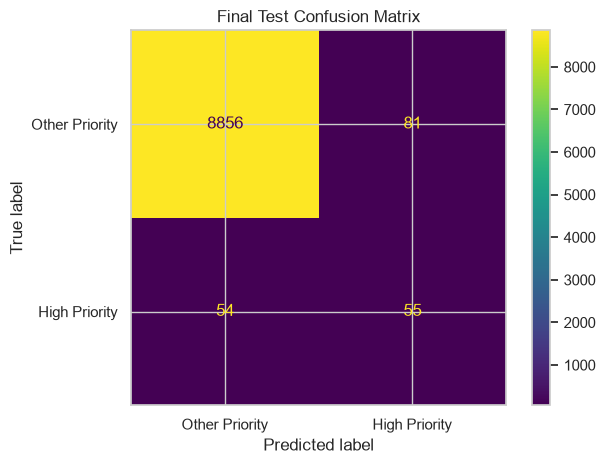

Confusion matrix [[TN, FP], [FN, TP]]:
[[8856   81]
 [  54   55]]


In [11]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    average_precision_score
)
import matplotlib.pyplot as plt

# Actual and predicted labels from the saved final test results
y_true = final_predictions["Actual_High_Priority"].astype(int)
y_pred = final_predictions["Predicted_High_Priority"].astype(int)
y_prob = final_predictions["Predicted_High_Priority_Probability"]

# Classification report
print("FINAL CHRONOLOGICAL TEST RESULTS")
print("Accuracy:", round(accuracy_score(y_true, y_pred), 4))
print("Average Precision:", round(average_precision_score(y_true, y_prob), 4))

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=["Other Priority (P3/P4/P5)", "High Priority (P1/P2)"],
    zero_division=0
))

# Confusion matrix
cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Other Priority", "High Priority"]
)

disp.plot()
plt.title("Final Test Confusion Matrix")
plt.tight_layout()
plt.show()

print("Confusion matrix [[TN, FP], [FN, TP]]:")
print(cm)

## 8. Key Findings

- The dataset contains 46,606 historical ITSM incident records and 25 columns.
- The priority classifier uses incident metadata and a validation-selected decision threshold of 0.90.
- On the chronological test set, the classifier achieved approximately 98.51% accuracy and a 0.45 F1-score for high-priority incidents.
- The previous-week baseline achieved an MAE of approximately 24.77 tickets, outperforming the tested Random Forest forecasting model.
- Results are based on historical 2012–2014 records and require validation on newer data before operational use.

## Project Resources

- GitHub Repository: https://github.com/sujal-5104/ABC-Tech-ITSM
- Live Dashboard: https://abc-tech-itsm.onrender.com

## Final Conclusion

This project demonstrates a complete ITSM analytics workflow combining data quality checks, exploratory analysis, machine learning classification, time-series forecasting, model evaluation, and interactive visualization. Future improvements include evaluating newer incident data, improving high-priority recall, and monitoring changes in incident patterns.